In [1]:
from matplotlib import pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import numpy as np
import pandas as pd
import os
import ast
from configparser import ConfigParser

In [2]:
DATAPATH = '../../data/output'
CONFIGPATH = '../configurations/app-remote.ini'

parser = ConfigParser()
parser.read(CONFIGPATH)

# Configuration
episodes = int(parser.get("BUS", "EPISODES"))
timelimit = parser.getfloat("BUS", "TIMELIMIT") # multiplier, not the real timelimit
actions = parser.get("BUS", "ACTION_SPACE").split(',')
action_dim = len(actions)
action_resolution = parser.getint("BUS", "ACTION_SPACE_RESOLUTION")
eps = parser.getfloat("BUS", "EPS")
eps_decay_strategy = parser.get("BUS", "EPS_DECAY_STRATEGY")
eps_decay = parser.getfloat("BUS", "EPS_DECAY")
eps_min = parser.getfloat("BUS", "EPS_MIN")
buffersize = int(parser.get("BUS", "BUFFERSIZE"))
min_experience = int(parser.get("BUS", "MIN_EXPERIENCE"))
target_update_threshold = int(parser.get("BUS", "TARGET_UPDATE_THRESHOLD"))
tau = parser.getfloat("BUS", "TAU")
gamma = parser.getfloat("BUS", "GAMMA")
penalty = int(parser.get("BUS", "PENALTY"))
reward = parser.getint("BUS", "REWARD")
q_net_layers = ast.literal_eval(parser.get("BUS", "DQN_LAYERS"))
batchsize = int(parser.get("BUS", "BATCHSIZE"))
lr_decay = parser.getboolean("BUS", "LR_DECAY")
lr_decay_steps = parser.getint("BUS", "LR_DECAY_STEPS")
velocity = float(parser.get("BUS", "VELOCITY"))

# Experiment with different agent configurations

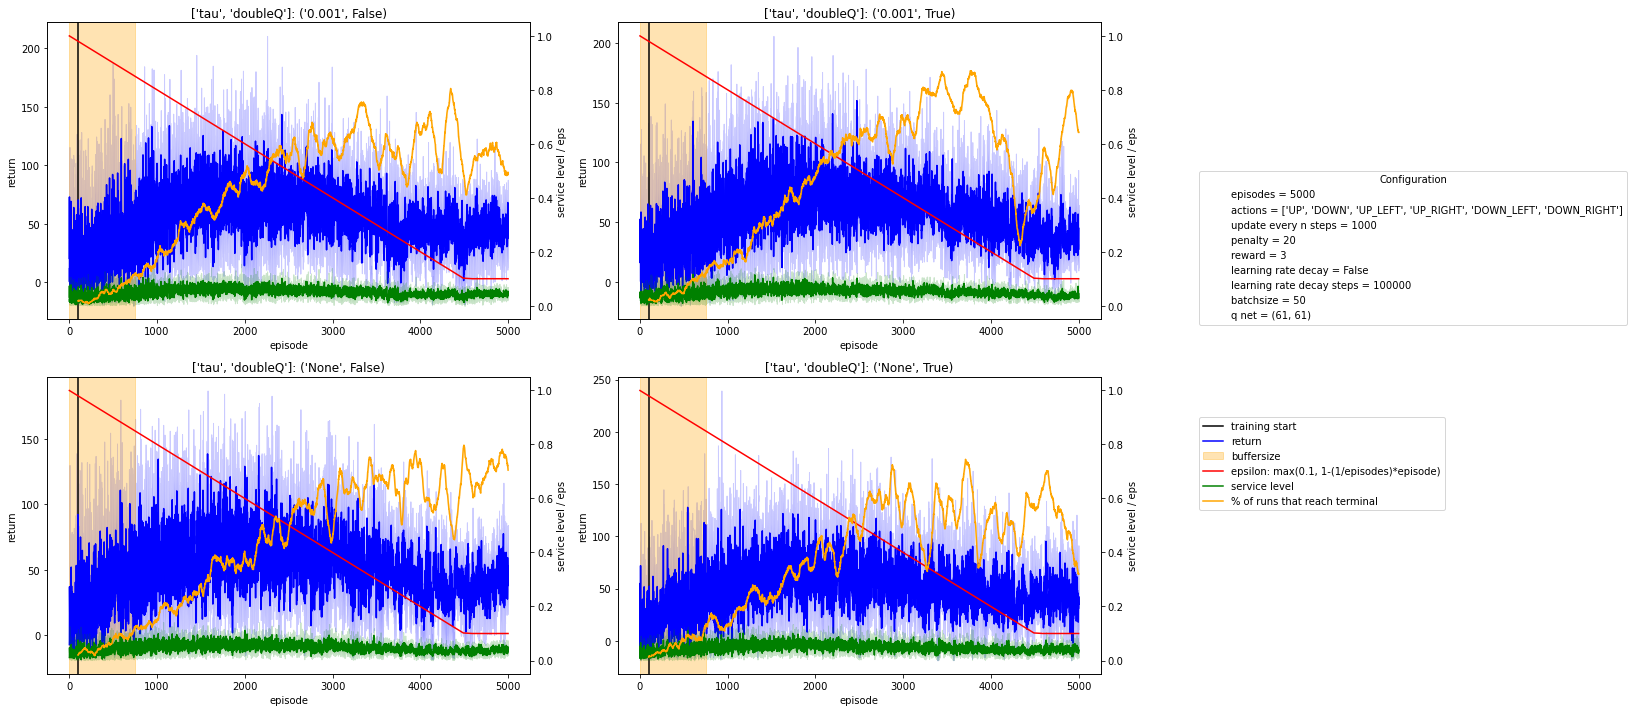

In [3]:
RESULTS = 'search_doubleQ_tau_experiments_20211229-065536.csv'
COLS = ['episode', 'return', 'service_level', 'lr', 'reached_destination', 'distance', 'duration']

config = {'episodes': episodes, 
          'actions': actions,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'learning rate decay': lr_decay,
          'learning rate decay steps': lr_decay_steps,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, 'returns', RESULTS))
experiments = list(set(results) - set(COLS))

for e in experiments:
    config.pop(e, None) # remove this from configuration legend

n_experiments = len(experiments)
if n_experiments > 2:
    raise NotImplementedError('more than two simultaneous experiments are currently not supported')
elif n_experiments == 2 and not 'eps_decay_strategy' in experiments:
    e1 = results[experiments[0]]
    e2 = results[experiments[1]]
    n_e1 = e1.nunique()
    n_e2 = e2.nunique()
    fig, ax = plt.subplots(n_e1, n_e2, figsize=(8*n_e1,5*n_e2))
    ii = 0
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()
        
        if i >= n_e1:
            ii = i // n_e1
            i -= n_e1

        # annotations
        if 'buffersize' in experiments:
            buffersize_i = experiments.index('buffersize')
            ax[ii][i].axvspan(0, name[buffersize_i], color='orange', alpha=.3, label='buffersize')
        else:
            ax[ii][i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[ii][i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[ii][i].twinx()
        ax2 = ax[ii][i].twinx()
        if 'eps_decay_strategy' in experiments:
            epsdecaystrategy_i = experiments.index('eps_decay_strategy')
            eps_decay_strategy = name[epsdecaystrategy_i]
        if eps_decay_strategy == 'exp':
            if 'eps_decay' in experiments:
                epsdecay_i = experiments.index('eps_decay')
                sns.lineplot(x=x_, y=np.maximum(name[epsdecay_i]**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {name}^episode)', legend=False)
            else:
                sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        if eps_decay_strategy == 'linear':
            sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)*x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
        if eps_decay_strategy == 'none':
            config.pop('eps_decay', None)
            config.pop('eps_min', None)
            config['eps'] = eps
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[ii][i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[ii][i].set_title(f'{experiments}: {name}')

    handles, labels = [(a + b) for a, b in zip(ax[ii][i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]

elif n_experiments == 1 or 'eps_decay_strategy' in experiments:
    if 'eps_decay_strategy' in experiments:
        i = experiments.index('eps_decay_strategy')
        n = results[experiments[i]].nunique()
        experiments = [experiments[i]]
    else:
        n = results[experiments[0]].nunique()
    fig, ax = plt.subplots(n, figsize=(10,5*n))
    
    for i, (name, group) in enumerate(results.groupby(experiments)):
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        if 'buffersize' in experiments:
            ax[i].axvspan(0, name, color='orange', alpha=.3, label='buffersize')
        else:
            ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        if 'eps_decay_strategy' in experiments:
            eps_decay_strategy = name
            eps_decay_col = list(group).index('eps_decay')
            group.iat[0, eps_decay_col]
        if eps_decay_strategy == 'exp':
            if 'eps_decay' in experiments:
                sns.lineplot(x=x_, y=np.maximum(name**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {name}^episode)', legend=False)
            else:
                sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        if eps_decay_strategy == 'linear':
            sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)*x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
        if eps_decay_strategy == 'none':
            config.pop('eps_decay', None)
            config.pop('eps_min', None)
            config['eps'] = eps
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', color='navy', label='return', ax=ax[i], legend=False)
    #         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
    #         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', linewidth=2, label='% of runs that reach terminal', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'{experiments[0]}: {name}')

    handles, labels = [(a + b) for a, b in zip(ax[i].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.35), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.65), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

# Single (averaged) agent evaluation

In [31]:
RESULTS = '5000_episodes_returns_20220104-031036.csv'
ROLLING = 100

config = {'episodes': episodes, 
          'actions': actions,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

results = pd.read_csv(os.path.join(DATAPATH, 'returns', RESULTS))

# %%
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(ROLLING).mean()
results['service_level_MA'] = results['service_level'].rolling(ROLLING).mean()
results['reached_destination_MA'] = results['reached_destination'].rolling(ROLLING).mean()

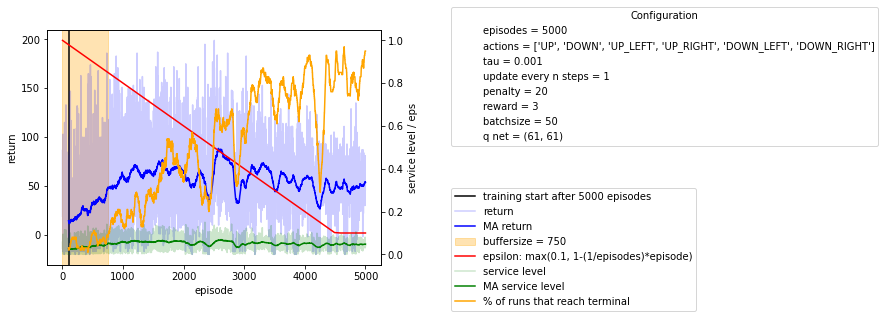

In [32]:
fig, ax = plt.subplots()
# annotations
plt.axvspan(0, buffersize, color='orange', alpha=.3, label=f'buffersize = {buffersize}')
plt.axvline(min_experience, color='black', label=f'training start after {episodes} episodes')
x_ = np.linspace(1,episodes)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
if eps_decay_strategy == 'exp':
    sns.lineplot(x=x_, y=np.maximum(0.9994**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
if eps_decay_strategy == 'linear':
    sns.lineplot(x=x_, y=np.maximum(1-(1/episodes)*x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, 1-(1/episodes)*episode)', legend=False)
ax_.set_axis_off() # hide this axis

if len(results) == episodes:
    # single agent
    sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax, legend=False)
    sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax, legend=False)
    sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
    sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
else:
    # multiple agents were evaluated at the same time for averaging
    sns.lineplot(data=results, x='episode', y='return', alpha=1, color='blue', label='return', ax=ax, legend=False)
    sns.lineplot(data=results, x='episode', y='service_level', alpha=1, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)

# plt.title('Experiment with tanh activation function in hidden layers')
ax2.set_ylabel('service level / eps')

handles, labels = [(a + b) for a, b in zip(ax.get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.2), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.8), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

## find best of runs

In [5]:
runs = [
    '5000_episodes_returns_20220104-024842.csv',
    '5000_episodes_returns_20220104-024844.csv',
    '5000_episodes_returns_20220104-031036.csv',
    '5000_episodes_returns_20220104-031329.csv',
    '5000_episodes_returns_20220104-032048.csv',
    '5000_episodes_returns_20220104-032910.csv',
    '5000_episodes_returns_20220104-033013.csv',
    '5000_episodes_returns_20220104-033110.csv',
    '5000_episodes_returns_20220104-033254.csv',
    '5000_episodes_returns_20220104-033831.csv',
    '5000_episodes_returns_20220104-034000.csv',
    '5000_episodes_returns_20220104-034410.csv',
    '5000_episodes_returns_20220104-034424.csv',
    '5000_episodes_returns_20220104-035042.csv',
    '5000_episodes_returns_20220104-040945.csv',
    '5000_episodes_returns_20220104-041715.csv',
    '5000_episodes_returns_20220104-043156.csv',
    '5000_episodes_returns_20220104-043914.csv',
    '5000_episodes_returns_20220104-045131.csv',
    '5000_episodes_returns_20220104-050622.csv',
]

In [6]:
LAST_N = 100

evaluate_results = []

for r in runs:
    run_results = pd.read_csv(os.path.join(DATAPATH, 'returns', r))
    e_cols = list(set(run_results) - set(['service_level', 'episode', 'reached_destination', 'lr', 'return']))
    evaluate_results.append(
        {'run': r,
         'mean_service': run_results["service_level"].mean(), 
         'last_mean_service': run_results["service_level"][-LAST_N:].mean(), 
         'reached_destination': run_results["reached_destination"].mean(), 
         'last_reached_destination': run_results["reached_destination"][-LAST_N:].mean(),
         'experiments': str(run_results.loc[0,e_cols].to_dict())}
    )
    # print(f'Run {r}: \n\tLast runs service level: {run_results["service_level"][-10:].mean()} \n\tLast runs of reaching destination: {run_results["reached_destination"][-10:].mean()}\n\tMean service level: {run_results["service_level"].mean()} \n\tMean of reaching destination: {run_results["reached_destination"].mean()}\n')

In [7]:
evaluate_results = pd.DataFrame.from_records(evaluate_results)
# evaluate_results.groupby('experiments').mean()

In [8]:
# filter out agents that do not reach the destination reliably
evaluate_results_filtered = evaluate_results[evaluate_results['last_reached_destination'] >= 0.8]
# filter out agents that are not stable
# evaluate_results_filtered = evaluate_results_filtered[evaluate_results_filtered['last_mean_service']>=evaluate_results_filtered['mean_service']]
evaluate_results_filtered

,run,mean_service,last_mean_service,reached_destination,last_reached_destination,experiments
0,5000_episodes_returns_20220104-024842.csv,0.048408,0.042814,0.5220,0.98,{}
1,5000_episodes_returns_20220104-024844.csv,0.051488,0.048513,0.5930,0.93,{}
2,5000_episodes_returns_20220104-031036.csv,0.049920,0.047862,0.4878,0.95,{}
4,5000_episodes_returns_20220104-032048.csv,0.047977,0.051021,0.4786,0.90,{}
7,5000_episodes_returns_20220104-033110.csv,0.049376,0.020592,0.4740,1.00,{}
10,5000_episodes_returns_20220104-034000.csv,0.053396,0.049549,0.5108,0.94,{}


In [30]:
evaluate_results_filtered.loc[12, 'run']

'5000_episodes_doubleQ=False_tau=0.001_returns_20211229-054142.csv'

# Benchmark best run

In [43]:
plt.rcParams.update({
    'axes.titlesize': 'xx-large',
    'axes.labelsize': 'x-large',
    'legend.fontsize': 'large',
    'legend.title_fontsize': 'large'
})

BENCHMARK_PATH = 'benchmarks'
# BENCHMARK = '100_episodes_benchmark_20220105-115141.csv' # BACKUP: currently used for results
BENCHMARK = '100_episodes_benchmark_20220106-155700.csv'
ROLLING = 1

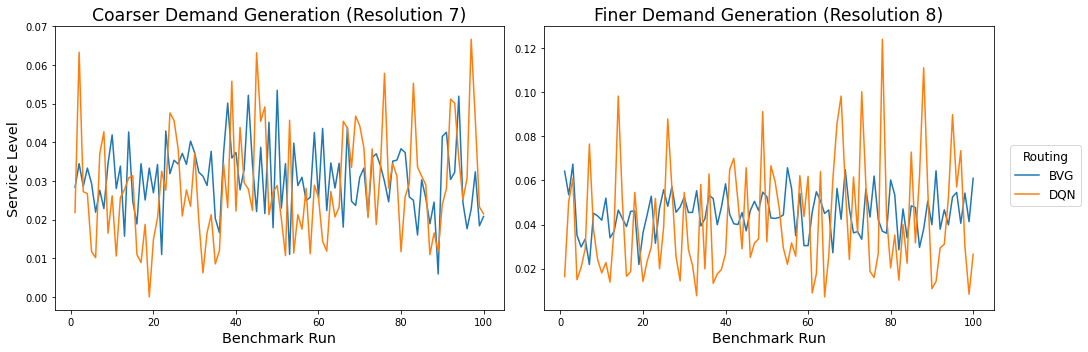

In [44]:
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK_PATH, BENCHMARK))
# noinspection JupyterPackage
# benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level'].rolling(ROLLING).mean()
# benchmark_results.loc[benchmark_results['type']=='BVG', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='BVG', 'service_level'].rolling(ROLLING).mean()

fig, ax = plt.subplots(1,2, figsize=(14,5))

sns.lineplot(ax=ax[0], data=benchmark_results[benchmark_results['spatial_res']==7], x='episode', y='service_level', hue='type')
ax[0].legend().remove()
ax[0].set_title('Coarser Demand Generation (Resolution 7)')
sns.lineplot(ax=ax[1], data=benchmark_results[benchmark_results['spatial_res']==8], x='episode', y='service_level', hue='type', legend=False)
ax[1].set_title('Finer Demand Generation (Resolution 8)')


for a in ax:
    a.set_xlabel('Benchmark Run')
ax[0].set_ylabel('Service Level')
ax[1].set_ylabel(None)

handles, labels = ax[0].get_legend_handles_labels()
fig.patch.set_facecolor('white')
fig.tight_layout()
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.0,0.5), loc="center left", title='Routing')

plt.savefig(os.path.join(DATAPATH, BENCHMARK_PATH, BENCHMARK.replace('.csv', '.png')), bbox_extra_artists=(lgd,), bbox_inches='tight')
plt.show()

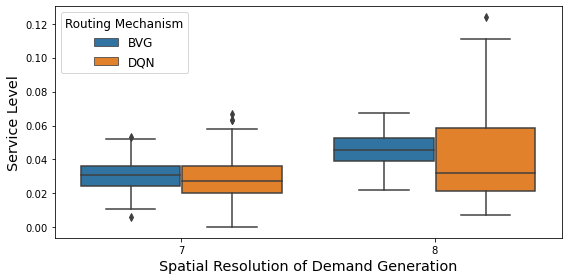

In [45]:
fig, ax = plt.subplots(1,1,figsize=(8,4))
sns.boxplot(ax=ax, data=benchmark_results, x='spatial_res', y='service_level', hue='type')
ax.set_xlabel('Spatial Resolution of Demand Generation')
ax.set_ylabel('Service Level')
ax.legend(title='Routing Mechanism')

fig.patch.set_facecolor('white')
fig.tight_layout()

plt.savefig(os.path.join(DATAPATH, BENCHMARK_PATH, BENCHMARK.replace('.csv', '_boxplot.png')), bbox_inches='tight')
plt.show()

In [37]:
benchmark_stats_full = benchmark_results.groupby(['type', 'spatial_res']).describe().drop(columns='episode').drop(columns=['count', 'std'], level=1)
benchmark_stats_min = benchmark_stats_full.loc[:,(['service_level', 'distance', 'duration'], 'mean')]
benchmark_stats_min.columns = benchmark_stats_min.columns.droplevel(level=1)

In [38]:
# inline table with means only
benchmark_stats_min.loc[:,'distance'] = benchmark_stats_min.loc[:,'distance'] / 1000
benchmark_stats_min.loc[:,'service_level'] = benchmark_stats_min.loc[:,'service_level'].map('{:.2%}'.format)
benchmark_stats_min.loc[('DQN',7),'reaching destination'] = '{:.0%}'.format(benchmark_results.loc[(benchmark_results['type']=='DQN') & (benchmark_results['spatial_res']==7), 'reached_destination'].mean())
benchmark_stats_min.loc[('DQN',8),'reaching destination'] = '{:.0%}'.format(benchmark_results.loc[(benchmark_results['type']=='DQN') & (benchmark_results['spatial_res']==8), 'reached_destination'].mean())
benchmark_stats_min.loc['BVG','reaching destination'] = '100%'
benchmark_stats_min

/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/indexing.py:1951: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self.obj[selected_item_labels] = value
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/indexing.py:1773: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(ilocs[0], value, pi)
/Users/janik/miniconda3/envs/urban-mobility-simulation/lib/python3.9/site-packages/pandas/core/indexing.py

service_level   distance   duration reaching destination
type spatial_res                                                         
BVG  7                   3.32%  12.358056  48.000000                 100%
     8                   4.54%  12.358056  48.000000                 100%
DQN  7                   4.07%  22.952683  45.905367                  57%
     8                   7.26%  21.828424  43.656847                  99%

In [39]:
COLUMN_FORMAT = 'llrrrr'

latex = benchmark_stats_min.to_latex(column_format=COLUMN_FORMAT, float_format="{:,.2f}".format, caption='Mean service, distance, and duration of 100 benchmark runs', label='tab:benchmarks', position='t')

# rename things
latex = latex.replace('type', 'Routing')
latex = latex.replace('service\_level', 'Service Level')
latex = latex.replace('spatial\_res', 'Demand$^{1}$')
latex = latex.replace('reaching destination', 'Terminal$^{2}$')
latex = latex.replace('distance', 'Distance (km)')
latex = latex.replace('duration', 'Duration (min)')
latex = latex.replace('\\centering', '\\setlength{\\tabcolsep}{4pt} \n\\centering')
notes = """
\\bottomrule
\multicolumn{6}{l}{\small $^{1}$Granularity of demand generation process, in h3 cell resolution.} \\\\ 
\multicolumn{6}{l}{\small $^{2}$Percentage of runs that arrive at the terminal destination in time.} \\\\
\\bottomrule"""
latex = latex.replace('\\bottomrule', notes)

with open(os.path.join(DATAPATH, 'figures', 'benchmark_small.tex'), 'w') as f:
    f.write(latex)
print(latex)

\begin{table}[t]
\setlength{\tabcolsep}{4pt} 
\centering
\caption{Mean service, Distance (km), and Duration (min) of 100 benchmark runs}
\label{tab:benchmarks}
\begin{tabular}{llrrrr}
\toprule
    &   & Service Level &  Distance (km) &  Duration (min) & Terminal$^{2}$ \\
Routing & Demand$^{1}$ &               &           &           &                      \\
\midrule
BVG & 7 &         3.32\% &     12.36 &     48.00 &                 100\% \\
    & 8 &         4.54\% &     12.36 &     48.00 &                 100\% \\
DQN & 7 &         4.07\% &     22.95 &     45.91 &                  57\% \\
    & 8 &         7.26\% &     21.83 &     43.66 &                  99\% \\

\bottomrule
\multicolumn{6}{l}{\small $^{1}$Granularity of demand generation process, in h3 cell resolution.} \\ 
\multicolumn{6}{l}{\small $^{2}$Percentage of runs that arrive at the terminal destination in time.} \\
\bottomrule
\end{tabular}
\end{table}



In [40]:
# benchmark_stats_full = benchmark_results.groupby(['type', 'spatial_res']).describe().drop(columns='episode').drop(columns=['count', 'std'], level=1)
benchmark_stats_full.loc[:,'service_level'] = benchmark_stats_full.loc[:,('service_level',)].applymap('{:.2%}'.format).values
benchmark_stats_full.loc[:,'distance'] = (benchmark_stats_full.loc[:,'distance'] / 1000).values
benchmark_stats_full.loc[('DQN',7),'destination'] = '{:.0%}'.format(benchmark_results.loc[(benchmark_results['type']=='DQN') & (benchmark_results['spatial_res']==7), 'reached_destination'].mean())
benchmark_stats_full.loc[('DQN',8),'destination'] = '{:.0%}'.format(benchmark_results.loc[(benchmark_results['type']=='DQN') & (benchmark_results['spatial_res']==8), 'reached_destination'].mean())
benchmark_stats_full.loc['BVG','destination'] = '100%'
benchmark_stats_full = benchmark_stats_full.T
benchmark_stats_full

type                      BVG                   DQN           
spatial_res                 7          8          7          8
service_level mean      3.32%      4.54%      4.07%      7.26%
              min       1.30%      2.07%      0.80%      3.03%
              25%       2.71%      4.01%      3.14%      6.25%
              50%       3.41%      4.52%      4.03%      7.32%
              75%       3.79%      4.98%      4.92%      8.22%
              max       5.79%      6.90%     10.67%     12.07%
distance      mean  12.358056  12.358056  22.952683  21.828424
              min   12.358056  12.358056  12.546527  13.361356
              25%   12.358056  12.358056  18.647081  18.547629
              50%   12.358056  12.358056  22.893097  21.236727
              75%   12.358056  12.358056  27.601963    24.7804
              max   12.358056  12.358056   35.33254   35.16116
duration      mean       48.0       48.0  45.905367  43.656847
              min        48.0       48.0  25.093054  26.722713
              25%        48.0       48.0  37.294162  37.095257
              50%        48.0       48.0  45.786194  42.473455
              75%        48.0       48.0  55.203926  49.560801
              max        48.0       48.0   70.66508   70.32232
destination              100%       100%        57%        99%

In [41]:
# check what quantile of DQN stays below or par BVG duration
from scipy import stats
stats.percentileofscore(benchmark_results.loc[(benchmark_results['type']=='DQN')&(benchmark_results['spatial_res']==8),'duration'], 48)

71.0

In [42]:
COLUMN_FORMAT = 'lllrrrr'

# dirty hack to move column multiindex labels to dummy column
benchmark_stats_full[('0', '0')] = ''

latex = benchmark_stats_full[['0','BVG','DQN']].to_latex(column_format=COLUMN_FORMAT, float_format="{:,.2f}".format, caption='Statistics of 100 benchmark runs', label='tab:benchmarks_full', position='t')

# rename things
latex = latex.replace('type & 0', ' & Routing')
latex = latex.replace('service\_level', 'Service Level')
latex = latex.replace('spatial\_res & 0', ' & Demand$^{1}$')
latex = latex.replace('destination', 'Terminal$^{2}$')
latex = latex.replace('distance', 'Distance (km)')
latex = latex.replace('duration', 'Duration (min)')
latex = latex.replace('\\centering', '\\setlength{\\tabcolsep}{4pt} \n\\centering')
notes = """
\\bottomrule
\multicolumn{7}{l}{\small $^{1}$Granularity of demand generation process, in h3 cell resolution.} \\\\ 
\multicolumn{7}{l}{\small $^{2}$Percentage of runs that arrive at the terminal destination in time.} \\\\
\\bottomrule"""
latex = latex.replace('\\bottomrule', notes)

with open(os.path.join(DATAPATH, 'figures', 'benchmark_full.tex'), 'w') as f:
    f.write(latex)
print(latex)

\begin{table}[t]
\setlength{\tabcolsep}{4pt} 
\centering
\caption{Statistics of 100 benchmark runs}
\label{tab:benchmarks_full}
\begin{tabular}{lllrrrr}
\toprule
            &  & Routing & \multicolumn{2}{l}{BVG} & \multicolumn{2}{l}{DQN} \\
            &  & Demand$^{1}$ &      7 &      8 &       7 &       8 \\
\midrule
Service Level & mean &   &  3.32\% &  4.54\% &   4.07\% &   7.26\% \\
            & min &   &  1.30\% &  2.07\% &   0.80\% &   3.03\% \\
            & 25\% &   &  2.71\% &  4.01\% &   3.14\% &   6.25\% \\
            & 50\% &   &  3.41\% &  4.52\% &   4.03\% &   7.32\% \\
            & 75\% &   &  3.79\% &  4.98\% &   4.92\% &   8.22\% \\
            & max &   &  5.79\% &  6.90\% &  10.67\% &  12.07\% \\
Distance (km) & mean &   &  12.36 &  12.36 &   22.95 &   21.83 \\
            & min &   &  12.36 &  12.36 &   12.55 &   13.36 \\
            & 25\% &   &  12.36 &  12.36 &   18.65 &   18.55 \\
            & 50\% &   &  12.36 &  12.36 &   22.89 &   21.24 \\
            &

# Code scrapyard

In [12]:
RESULTS = [
    '5000_episodes_returns_20211216-021413.csv',
    '5000_episodes_returns_20211216-030028.csv',
    '5000_episodes_returns_20211216-030903.csv',
    '5000_episodes_returns_20211216-031023.csv',
    '5000_episodes_returns_20211216-034113.csv',
    '5000_episodes_returns_20211216-041024.csv',
    '5000_episodes_returns_20211216-041230.csv',
    '5000_episodes_returns_20211216-041816.csv',
    '5000_episodes_returns_20211216-042849.csv',
    '5000_episodes_returns_20211216-043242.csv',
    '5000_episodes_returns_20211216-044310.csv',
    '5000_episodes_returns_20211216-044529.csv',
    '5000_episodes_returns_20211216-050700.csv',
    '5000_episodes_returns_20211216-050900.csv',
    '5000_episodes_returns_20211216-050953.csv',
    '5000_episodes_returns_20211216-051702.csv',
    '5000_episodes_returns_20211216-052029.csv',
    '5000_episodes_returns_20211216-052151.csv',
    '5000_episodes_returns_20211216-052437.csv',
    '5000_episodes_returns_20211216-054150.csv'
]

re = []

for r in RESULTS:
    re.append(pd.read_csv(os.path.join(DATAPATH, r)))
    
results = pd.concat(re, axis=0, ignore_index=True)
results.to_csv(os.path.join(DATAPATH,'search_reward_experiments_20211216-000000.csv'), index=False)

<AxesSubplot:label='2cc29999-6d10-4bc8-a731-3086deb3bf5c', xlabel='episode', ylabel='reached_destination'>

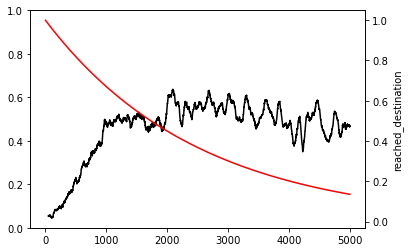

In [57]:
fig, ax = plt.subplots()
# sns.lineplot(ax=ax, data=results, x='episode', y='return', hue='reached_destination')
reached = results.groupby('episode')['reached_destination'].mean().rolling(50).mean().reset_index()
ax2 = ax.twinx()
sns.lineplot(ax=ax2, data=reached, x='episode', y='reached_destination', color='black', alpha=1)
sns.lineplot(x=x_, y=np.maximum(0.9996**x_, eps_min), color='red', ax=ax2)